130k_v2_csv     -> shape: (129971, 13), columns: ['country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'taster_name', 'taster_twitter_handle', 'title', 'variety', 'winery']
130k_v2_json    -> shape: (129971, 13), columns: ['points', 'title', 'description', 'taster_name', 'taster_twitter_handle', 'price', 'designation', 'variety', 'region_1', 'region_2', 'province', 'country', 'winery']
first150k_csv   -> shape: (150930, 10), columns: ['country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']

Summary stats (130k v2 CSV):


,points,price,points_per_dollar
count,119988.000000,119988.000000,119988.000000
mean,88.442236,35.132563,3.821060
std,3.092915,40.761385,2.177131
min,80.000000,4.000000,0.026667
25%,86.000000,17.000000,2.153846
50%,88.000000,26.000000,3.423077
75%,91.000000,42.000000,5.058824
max,100.000000,3300.000000,21.500000



Top 10 Countries:


,count
country,
US,50457
France,20353
Italy,17940
Spain,6116
Portugal,5256
Chile,4184
Argentina,3544
Austria,3034
Australia,2197



Top 10 Varieties:


,count
variety,
Pinot Noir,12278
Chardonnay,10868
Cabernet Sauvignon,8840
Red Blend,8243
Bordeaux-style Red Blend,6471
Riesling,4773
Sauvignon Blanc,4575
Syrah,3828
Rosé,3220


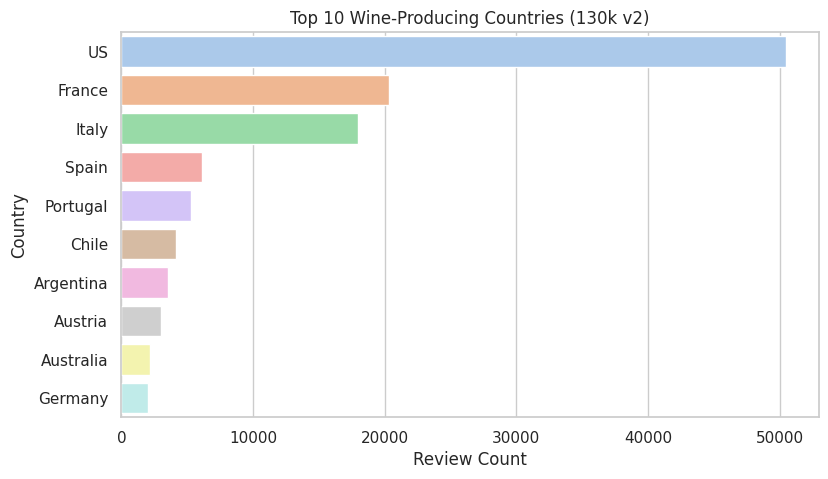

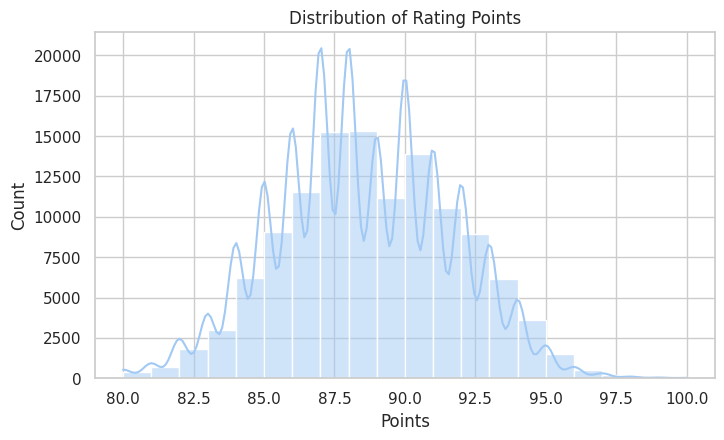

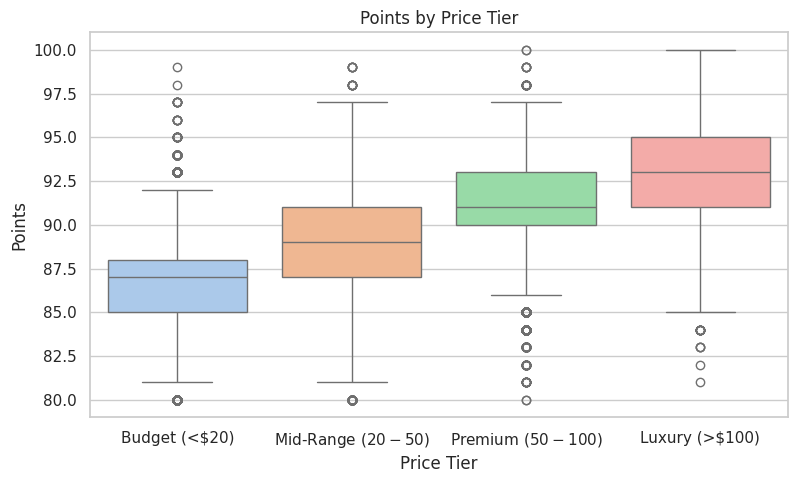

--- CONCLUSIONS ---
1. Dataset sizes after deduplication: 130k CSV=119,988, 130k JSON=119,988, 150k CSV=97,851.
2. Leading producer: US (50,457 reviews).
3. Price vs. points correlation: r = 0.40.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="pastel")
plt.rcParams["figure.figsize"] = (9, 5)

# ==========================================
# 1. Load All Three Archive Files
# ==========================================
# Adjust paths if extracted into a folder (e.g., "./wine_archive/...")
df_130k_csv = pd.read_csv("winemag-data-130k-v2.csv", index_col=0)
df_130k_json = pd.read_json("winemag-data-130k-v2.json")
df_150k_csv = pd.read_csv("winemag-data_first150k.csv", index_col=0)

datasets = {
    "130k_v2_csv": df_130k_csv,
    "130k_v2_json": df_130k_json,
    "first150k_csv": df_150k_csv,
}

for name, d in datasets.items():
    print(f"{name:15s} -> shape: {d.shape}, columns: {list(d.columns)}")

# ==========================================
# 2. Data Cleaning & Preprocessing Function
# ==========================================
def clean_wine_df(raw_df):
    d = raw_df.copy()
    d = d.drop_duplicates().reset_index(drop=True)

    cat_cols = [c for c in ["country", "province", "region_1", "region_2", "variety", "winery", "taster_name"] if c in d.columns]
    for col in cat_cols:
        d[col] = d[col].fillna("Unknown")

    if "price" in d.columns:
        if "variety" in d.columns:
            d["price"] = d["price"].fillna(d.groupby("variety")["price"].transform("median"))
        d["price"] = d["price"].fillna(d["price"].median())
        d["points_per_dollar"] = d["points"] / d["price"]
        d["price_tier"] = pd.cut(
            d["price"],
            bins=[0, 20, 50, 100, np.inf],
            labels=["Budget (<$20)", "Mid-Range ($20-$50)", "Premium ($50-$100)", "Luxury (>$100)"]
        )
    return d

cleaned = {name: clean_wine_df(d) for name, d in datasets.items()}

# Primary analysis DataFrame (130k v2 CSV)
df = cleaned["130k_v2_csv"]

# ==========================================
# 3. Exploratory Data Analysis (EDA)
# ==========================================
print("\nSummary stats (130k v2 CSV):")
display(df[["points", "price", "points_per_dollar"]].describe())

print("\nTop 10 Countries:")
top_countries = df["country"].value_counts().head(10)
display(top_countries)

print("\nTop 10 Varieties:")
display(df["variety"].value_counts().head(10))

# ==========================================
# 4. Visualizations
# ==========================================
plt.figure(figsize=(9, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, legend=False)
plt.title("Top 10 Wine-Producing Countries (130k v2)")
plt.xlabel("Review Count")
plt.ylabel("Country")
plt.show()

plt.figure(figsize=(8, 4.5))
sns.histplot(df["points"], bins=20, kde=True)
plt.title("Distribution of Rating Points")
plt.xlabel("Points")
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="price_tier", y="points", hue="price_tier", legend=False)
plt.title("Points by Price Tier")
plt.xlabel("Price Tier")
plt.ylabel("Points")
plt.show()

# ==========================================
# 5. Conclusions & Save Processed Output
# ==========================================
print("--- CONCLUSIONS ---")
print(f"1. Dataset sizes after deduplication: 130k CSV={len(cleaned['130k_v2_csv']):,}, 130k JSON={len(cleaned['130k_v2_json']):,}, 150k CSV={len(cleaned['first150k_csv']):,}.")
print(f"2. Leading producer: {top_countries.index[0]} ({top_countries.iloc[0]:,} reviews).")
print(f"3. Price vs. points correlation: r = {df[['points', 'price']].corr().iloc[0, 1]:.2f}.")

# Save a cleaned CSV export if needed
df.to_csv("wine_reviews_130k_cleaned.csv", index=False)